In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import skfuzzy as fuzz
import sys
import os

sys.path.append(os.path.abspath(".."))

from src.data.load_master_data import load_master_data

df = load_master_data()

print(f"Shape: {df.shape}")
display(df.head())

/Users/victoriaolsen/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/victoriaolsen/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


Shape: (25939, 46)


,season,round,driver_id,driver_name,constructor_id,grid,position,points,laps,status,...,podium,win,pole_position,front_row,weighted_points_at_circuit,driver_circuit_delta,points_last_5_races,current_season_points,avg_points_per_season,constructor_points_current_season
0,1950,1,farina,Nino Farina,alfa,1,1,9.0,70,Finished,...,1,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0
1,1950,1,fagioli,Luigi Fagioli,alfa,2,2,6.0,70,Finished,...,1,0,0,1,0.0,0.0,0.0,0.0,0.0,0.0
2,1950,1,reg_parnell,Reg Parnell,alfa,4,3,4.0,70,Finished,...,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,1950,1,cabantous,Yves Cabantous,lago,6,4,3.0,68,+2 Laps,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
4,1950,1,rosier,Louis Rosier,lago,9,5,2.0,68,+2 Laps,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
#choose numerical features that describes the drivers performance

cluster_features = [
    "grid",
    "points",
    "driver_age",
    "current_season_points",
    "avg_points_per_season",
    "points_last_5_races",
    "weighted_points_at_circuit",
    "driver_circuit_delta",
    "q1_seconds",
    "q2_seconds",
    "q3_seconds"
]

# Lag subset
cluster_df = df[cluster_features].copy()

print("Shape:", cluster_df.shape)
print("\nManglende verdier:")
print(cluster_df.isnull().sum())

Shape: (25939, 11)

Manglende verdier:
grid                          0
points                        0
driver_age                    0
current_season_points         0
avg_points_per_season         0
points_last_5_races           0
weighted_points_at_circuit    0
driver_circuit_delta          0
q1_seconds                    0
q2_seconds                    0
q3_seconds                    0
dtype: int64


In [4]:
# Fyll NaN med median per kolonne
for col in cluster_features:
    cluster_df[col] = cluster_df[col].fillna(
        cluster_df[col].median()
    )

print("NaN etter fylling:")
print(cluster_df.isnull().sum())

NaN etter fylling:
grid                          0
points                        0
driver_age                    0
current_season_points         0
avg_points_per_season         0
points_last_5_races           0
weighted_points_at_circuit    0
driver_circuit_delta          0
q1_seconds                    0
q2_seconds                    0
q3_seconds                    0
dtype: int64


In [5]:
#scale data
#Fuzzy-C means more sensitive for scale, coloumns with big numbers will dominate

scaler = StandardScaler()

X_scaled = scaler.fit_transform(cluster_df)

print("Skalert data shape:", X_scaled.shape)
print("Snitt per kolonne (skal være ~0):", X_scaled.mean(axis=0).round(2))
print("Std per kolonne (skal være ~1):", X_scaled.std(axis=0).round(2))

Skalert data shape: (25939, 11)
Snitt per kolonne (skal være ~0): [ 0.  0.  0. -0. -0.  0. -0. -0.  0. -0. -0.]
Std per kolonne (skal være ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


k=2: Silhouette Score = 0.5132
k=3: Silhouette Score = 0.3629
k=4: Silhouette Score = 0.2721
k=5: Silhouette Score = 0.2221
k=6: Silhouette Score = 0.2304
k=7: Silhouette Score = 0.2318


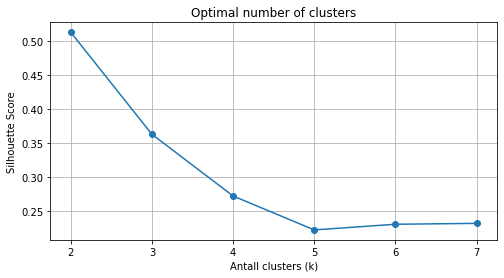


Beste antall clusters: 2


In [6]:
#find optimal number of clusters with silhouette score, 1 is good, negative is bad

from sklearn.cluster import KMeans

silhouette_scores = []
k_values = range(2, 8)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"k={k}: Silhouette Score = {score:.4f}")

# Plot
plt.figure(figsize=(8, 4))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Antall clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Optimal number of clusters")
plt.grid(True)
plt.show()

best_k = k_values[np.argmax(silhouette_scores)]
print(f"\nBeste antall clusters: {best_k}")

In [ ]:
#FCM

n_clusters = best_k
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    X_scaled.T,      # transponed
    c=n_clusters,   
    m=2,       
    error=0.005,    
    maxiter=1000,   
    init=None       
)

print(f"FPC (Fuzzy Partition Coefficient): {fpc:.4f}")
print("FPC nær 1.0 = tydelige clusters, nær 0 = overlappende")
print(f"\nMedlemskapsmatrise shape: {u.shape}")
print("(antall clusters x antall rader)")

FPC (Fuzzy Partition Coefficient): 0.6818
FPC nær 1.0 = tydelige clusters, nær 0 = overlappende

Medlemskapsmatrise shape: (2, 25939)
(antall clusters x antall rader)


In [ ]:

membership_df = pd.DataFrame(
    u.T,
    columns=[f"cluster_{i}_membership" for i in range(n_clusters)]
)

# which cluster is strongest?
membership_df["dominant_cluster"] = np.argmax(u, axis=0)

print("Fordeling av dominant cluster:")
print(membership_df["dominant_cluster"].value_counts())

print("\nEksempel på medlemskapsgrader:")
print(membership_df.head(10))

Fordeling av dominant cluster:
dominant_cluster
1    20309
0     5630
Name: count, dtype: int64

Eksempel på medlemskapsgrader:
   cluster_0_membership  cluster_1_membership  dominant_cluster
0              0.369420              0.630580                 1
1              0.395024              0.604976                 1
2              0.238188              0.761812                 1
3              0.303975              0.696025                 1
4              0.267519              0.732481                 1
5              0.096493              0.903507                 1
6              0.233123              0.766877                 1
7              0.350101              0.649899                 1
8              0.047630              0.952370                 1
9              0.100038              0.899962                 1


In [ ]:
df_clustered = df.copy()

for i in range(n_clusters):
    df_clustered[f"cluster_{i}_membership"] = u[i]

df_clustered["dominant_cluster"] = np.argmax(u, axis=0)

print(df_clustered[["driver_id", "season", "dominant_cluster"] +
      [f"cluster_{i}_membership" for i in range(n_clusters)]].head(10))

     driver_id  season  dominant_cluster  cluster_0_membership  \
0       farina    1950                 1              0.369420   
1      fagioli    1950                 1              0.395024   
2  reg_parnell    1950                 1              0.238188   
3    cabantous    1950                 1              0.303975   
4       rosier    1950                 1              0.267519   
5       gerard    1950                 1              0.096493   
6     harrison    1950                 1              0.233123   
7    etancelin    1950                 1              0.350101   
8    hampshire    1950                 1              0.047630   
9          fry    1950                 1              0.100038   

   cluster_1_membership  
0              0.630580  
1              0.604976  
2              0.761812  
3              0.696025  
4              0.732481  
5              0.903507  
6              0.766877  
7              0.649899  
8              0.952370  
9            

In [17]:

for cluster in range(n_clusters):
    print(f"\n{'='*50}")
    print(f"CLUSTER {cluster}")
    print(f"{'='*50}")

    cluster_data = df_clustered[
        df_clustered["dominant_cluster"] == cluster
    ]

    print(f"Number of rows: {len(cluster_data)}")
    print(f"\nAverage grid-position: {cluster_data['grid'].mean():.1f}")
    print(f"Average points pr race: {cluster_data['points'].mean():.2f}")
    print(f"Podium-rate: {cluster_data['podium'].mean():.2%}")
    print(f"Victory-rate: {cluster_data['win'].mean():.2%}")

    print(f"\nTopp 10 drivers in cluster:")
    top_drivers = (
        cluster_data.groupby("driver_id")["points"]
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )
    print(top_drivers)


CLUSTER 0
Number of rows: 5630

Average grid-position: 6.9
Average points pr race: 6.86
Podium-rate: 27.74%
Victory-rate: 10.89%

Topp 10 drivers in cluster:
driver_id
max_verstappen    14.626106
hamilton          13.132895
piastri           10.955224
vettel            10.893993
berger            10.000000
alesi             10.000000
russell            9.813725
leclerc            9.812121
norris             9.202703
rosberg            9.130058
Name: points, dtype: float64

CLUSTER 1
Number of rows: 20309

Average grid-position: 13.0
Average points pr race: 0.85
Podium-rate: 9.43%
Victory-rate: 2.67%

Topp 10 drivers in cluster:
driver_id
george_amick    6.000000
fangio          4.558148
wallard         4.500000
fagioli         4.000000
antonelli       4.000000
vukovich        3.800000
clark           3.449275
farina          3.441351
stewart         3.406250
prost           3.397059
Name: points, dtype: float64


/var/folders/s6/b3_f2shn28qbrxl3tf7rs7lc0000gn/T/ipykernel_28183/542776890.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_data.groupby("driver_id")["points"]


Explained varians: [0.46027756 0.13333426]
Total explained varians: 59.36%


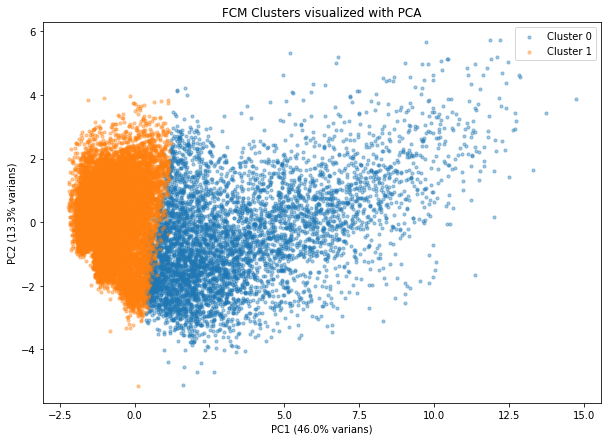

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Explained varians: {pca.explained_variance_ratio_}")
print(f"Total explained varians: {pca.explained_variance_ratio_.sum():.2%}")

plt.figure(figsize=(10, 7))

for cluster in range(n_clusters):
    mask = df_clustered["dominant_cluster"] == cluster
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.4,
        s=10
    )

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} varians)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} varians)")
plt.title("FCM Clusters visualized with PCA")
plt.legend()
plt.show()

                  avg_grid  avg_points  podium_rate  win_rate  \
dominant_cluster                                                
0                    6.893       6.855        0.277     0.109   
1                   13.046       0.853        0.094     0.027   

                  avg_season_points  count  
dominant_cluster                            
0                            62.310   5630  
1                             5.973  20309  


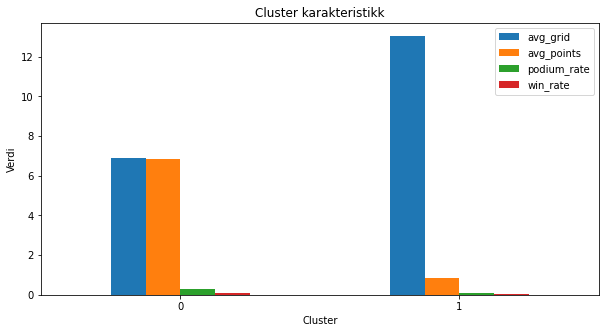

In [ ]:
cluster_summary = df_clustered.groupby("dominant_cluster").agg(
    avg_grid          = ("grid", "mean"),
    avg_points        = ("points", "mean"),
    podium_rate       = ("podium", "mean"),
    win_rate          = ("win", "mean"),
    avg_season_points = ("current_season_points", "mean"),
    count             = ("driver_id", "count")
).round(3)

print(cluster_summary)

cluster_summary[["avg_grid", "avg_points", "podium_rate", "win_rate"]].plot(
    kind="bar",
    figsize=(10, 5),
    title="Cluster karakteristikk"
)
plt.xlabel("Cluster")
plt.ylabel("Verdi")
plt.xticks(rotation=0)
plt.legend(loc="upper right")
plt.show()

In [ ]:
membership_cols = [f"cluster_{i}_membership" for i in range(n_clusters)]

df_clustered["max_membership"] = df_clustered[membership_cols].max(axis=1)
df_clustered["min_membership"] = df_clustered[membership_cols].min(axis=1)

fuzzy_drivers = df_clustered[
    df_clustered["max_membership"] < 0.6
][["driver_id", "season", "round", "dominant_cluster"] + membership_cols].head(20)

print("Drivers with uncertain cluster-dependency (fuzzy):")
print(fuzzy_drivers)

Drivers with uncertain cluster-dependency (fuzzy):
    driver_id  season  round  dominant_cluster  cluster_0_membership  \
33     farina    1950      2                 1              0.426006   
34    fagioli    1950      2                 1              0.406547   
79     farina    1950      4                 1              0.411576   
80    fagioli    1950      4                 1              0.408178   
98    fagioli    1950      5                 1              0.422092   
100    farina    1950      5                 1              0.418755   
111    fangio    1950      6                 1              0.415204   
112   fagioli    1950      6                 1              0.433202   
131    farina    1950      7                 1              0.424511   
134   fagioli    1950      7                 1              0.431237   
160    fangio    1951      1                 1              0.421659   
162    farina    1951      1                 1              0.440462   
215    farina

In [ ]:
print("Cluster 0 - Eksempel sjåfører:")
print(
    df_clustered[df_clustered["dominant_cluster"] == 0]
    ["driver_id"].value_counts().head(10)
)

print("\nCluster 1 - Eksempel sjåfører:")
print(
    df_clustered[df_clustered["dominant_cluster"] == 1]
    ["driver_id"].value_counts().head(10)
)

if n_clusters > 2:
    print("\nCluster 2 - Eksempel sjåfører:")
    print(
        df_clustered[df_clustered["dominant_cluster"] == 2]
        ["driver_id"].value_counts().head(10)
    )

Cluster 0 - Eksempel sjåfører:
driver_id
hamilton              380
alonso                359
vettel                283
raikkonen             268
perez                 238
michael_schumacher    230
max_verstappen        226
bottas                216
ricciardo             204
massa                 203
Name: count, dtype: int64

Cluster 1 - Eksempel sjåfører:
driver_id
patrese        257
barrichello    230
cesaris        209
berger         208
coulthard      205
piquet         203
alesi          201
trulli         198
alboreto       194
fisichella     194
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import silhouette_score

fcm_labels = np.argmax(u, axis=0)
fcm_silhouette = silhouette_score(X_scaled, fcm_labels)

print(f"FCM Silhouette Score: {fcm_silhouette:.4f}")
print(f"FPC: {fpc:.4f}")

print("Silhouette > 0.5 = clear clusters")
print("Silhouette 0.2-0.5 = moderate clusters")
print("Silhouette < 0.2 = weak clusters")

FCM Silhouette Score: 0.4450
FPC: 0.6818
Silhouette > 0.5 = clear clusters
Silhouette 0.2-0.5 = moderate clusters
Silhouette < 0.2 = weak clusters
